In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from torch import lt

# Cargar imagen en escala de grises (usa una de las imagen de tu mini reto
#que tomaste, luego la cambias por alguna de las imágenes binarias que
#creaste)

imagen = cv2.imread('Segmentacion_media.png', cv2.IMREAD_GRAYSCALE)


## Filtro paso bajas

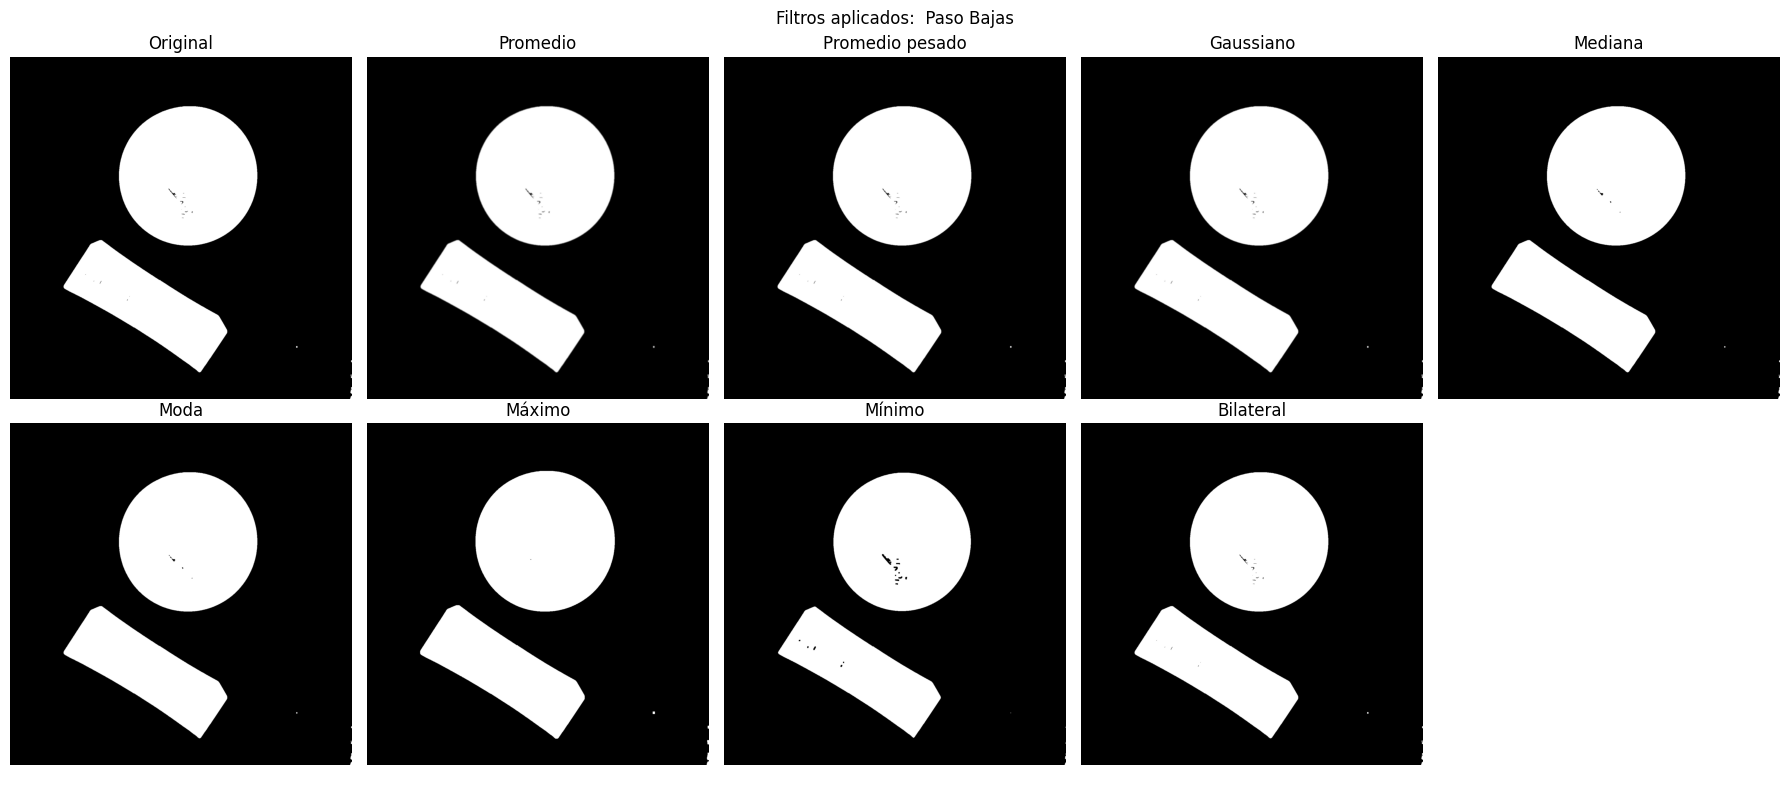

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

imagen = cv2.imread('filtro_maximo.png', cv2.IMREAD_GRAYSCALE)
def filtro_moda(imagen, tamano=5):
    def moda(vecindario):
        frecuencias = np.bincount(vecindario.astype(np.uint8), minlength=256)
        return np.argmax(frecuencias)

    return ndimage.generic_filter(
        imagen, moda, size=tamano, mode="reflect"
    ).astype(np.uint8)

def aplicar_filtros(imagen):
    kernel_pesado = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16

    kernel = np.ones((5, 5), dtype=np.uint8)

    return [
        imagen,
        cv2.blur(imagen, (5, 5)),
        cv2.filter2D(imagen, -1, kernel_pesado),
        cv2.GaussianBlur(imagen, (5, 5), 0),
        cv2.medianBlur(imagen, 5),
        filtro_moda(imagen, 5),
        cv2.dilate(imagen, kernel),
        cv2.erode(imagen, kernel),
        cv2.bilateralFilter(imagen, 9, 75, 75)
    ]

nombres_filtros = [
    "Original", "Promedio", "Promedio pesado", "Gaussiano",
    "Mediana", "Moda", "Máximo", "Mínimo", "Bilateral"
]

img_pneg = imagen_sal_pimienta

def mostrar_matriz(imagen_ruido, nombre):
    resultados = aplicar_filtros(imagen_ruido)
    if not cv2.imwrite("filtro_minimo.png", resultados[7]):
        raise OSError("No se pudo guardar filtro_minimo.png")

    fig, axs = plt.subplots(2, 5, figsize=(18, 8))
    axs = axs.ravel()

    for ax, resultado, titulo in zip(axs, resultados, nombres_filtros):
        ax.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        ax.set_title(titulo)
        ax.axis("off")

    # Ocultar la décima posición, que queda vacía
    axs[9].axis("off")

    fig.suptitle(f"Filtros aplicados:  {nombre}")
    plt.tight_layout()
    plt.show()


mostrar_matriz(imagen, "Paso Bajas")

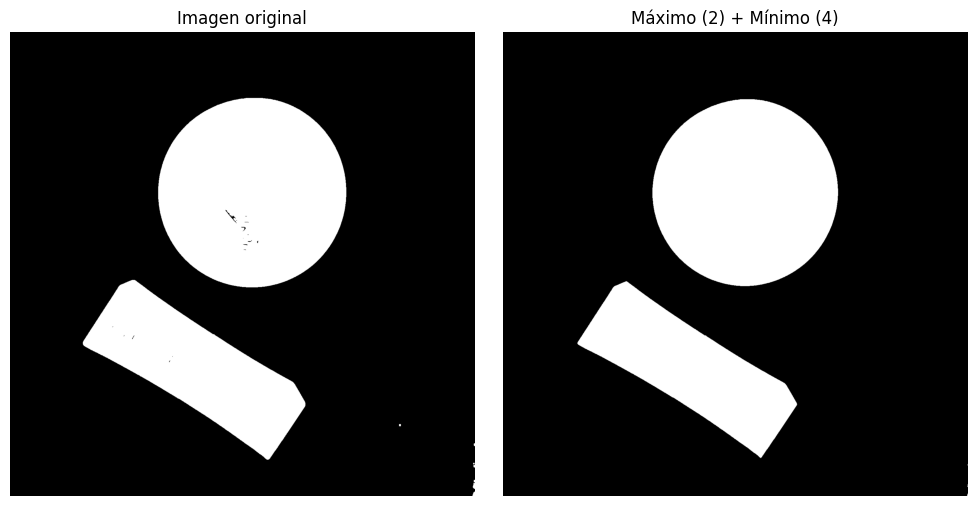

True

In [10]:
def filtro_maximo_minimo(imagen):
    kernel = np.ones((5, 5), dtype=np.uint8)

    # Aplicar filtro de máximo dos veces
    maximo_1 = cv2.dilate(imagen, kernel)
    maximo_2 = cv2.dilate(maximo_1, kernel)

    # Aplicar filtro de mínimo dos veces
    minimo_1 = cv2.erode(maximo_2, kernel)
    minimo_2 = cv2.erode(minimo_1, kernel)
    minimo_3 = cv2.erode(minimo_2, kernel)
    minimo_4 = cv2.erode(minimo_3, kernel)


    return minimo_4

resultado = filtro_maximo_minimo(imagen)


plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resultado, cmap="gray", vmin=0, vmax=255)
plt.title("Máximo (2) + Mínimo (4)")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("filtro_maximo_minimo.png", resultado)

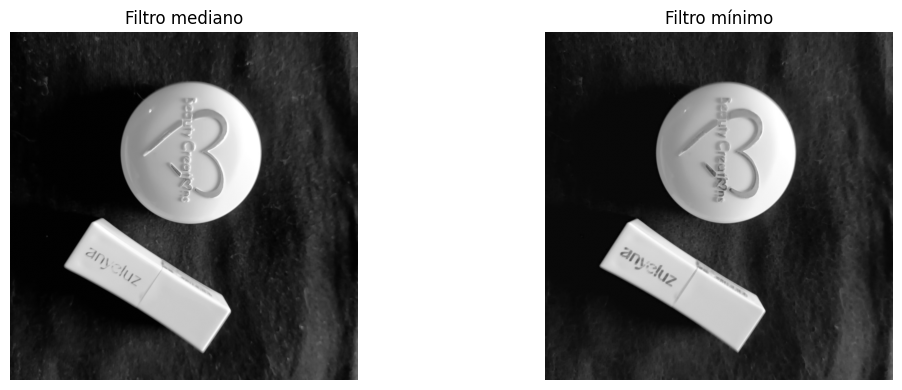

In [9]:
#Mostrar resultado de los filtros medio y filtro minimo
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(cv2.medianBlur(imagen, 5), cmap='gray')
axs[0].set_title('Filtro mediano')
axs[0].axis('off')
axs[1].imshow(cv2.erode(imagen, np.ones((5, 5), dtype=np.uint8)), cmap='gray')
axs[1].set_title('Filtro mínimo')
axs[1].axis('off')
plt.tight_layout()
plt.show()

#Gaurdar la imagen resultante del filtro minimo
if not cv2.imwrite("filtro_minimo.png", cv2.erode(imagen, np.ones((5, 5), dtype=np.uint8))):
    raise OSError("No se pudo guardar filtro_minimo.png")
